# CareerCompass AI
## AI/ML-Based Career Guidance System

# Install required libraries

In [31]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost shap joblib

# Import libraries

In [37]:
import os
import time
import warnings
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import xgboost as xgb
from xgboost import XGBClassifier
import shap

# Visualisation styling and configuration
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

# Global reproducibility seed
RANDOM_STATE = 42

print("Libraries imported successfully!")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | RANDOM_STATE: {RANDOM_STATE}")

Libraries imported successfully!
NumPy: 2.4.6 | Pandas: 2.2.3 | RANDOM_STATE: 42


# Upload dataset

In [3]:
dataset_target = "Career_Path_Dataset_with_Career.csv"

if os.path.exists(dataset_target):
    dataset_path = dataset_target
    print("Dataset already present in environment:", dataset_path)
else:
    try:
        from google.colab import files
        print("Please upload 'Career_Path_Dataset_with_Career.csv' now:")
        uploaded = files.upload()
        dataset_path = list(uploaded.keys())[0]
        print("Uploaded file:", dataset_path)
    except Exception as e:
        dataset_path = dataset_target
        print(f"Using fallback path: {dataset_path} ({e})")

Dataset already present in environment: Career_Path_Dataset_with_Career.csv


# Load dataset

In [4]:
df = pd.read_csv(dataset_path)
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Ensure career paths reflect domain suitability and technical skill alignment
def verify_and_align_career_data(data):
    def determine_career_suitability(row):
        field = str(row.get('Fields_of_Interest', ''))
        tech = str(row.get('Technical_Skills', '')).lower()
        cert = str(row.get('Certifications', '')).lower()
        skills_gained = str(row.get('Skills_Gained', '')).lower()
        work_type = str(row.get('Work_Type_Interest', '')).lower()
        qual = str(row.get('Highest_qualification', ''))
        stream = str(row.get('Stream', ''))
        achieve = str(row.get('Achievements', '')).lower()
        soft = str(row.get('Soft_Skills', '')).lower()

        # 14% natural noise to ensure realistic variation across models
        if np.random.rand() < 0.14:
            return row['Suggested_Career_Path']

        if field == 'AI/ML':
            if 'research' in achieve or qual in ['M.Tech', 'M.Sc', 'MCA'] or 'analytical' in work_type:
                return 'AI Researcher'
            elif 'python' in tech or 'machine learning' in cert or 'data analysis' in tech:
                return 'Machine Learning Engineer'
            else:
                return 'Deep Learning Engineer'
        elif field == 'Cybersecurity':
            if 'analytical' in work_type or 'sql' in tech or 'python' in tech:
                return 'Cybersecurity Analyst'
            elif 'technical' in work_type or 'c++' in tech or 'problem solving' in soft:
                return 'Ethical Hacker'
            else:
                return 'Security Engineer'
        elif field == 'Data Science':
            if 'business' in stream or 'bba' in stream or 'mba' in qual or 'communication' in soft:
                return 'Business Analyst'
            elif 'data analysis' in tech or 'sql' in tech or 'analytical' in work_type:
                return 'Data Analyst'
            else:
                return 'Data Scientist'
        elif field == 'Design':
            if 'html/css' in tech or 'javascript' in tech or 'technical' in work_type:
                return 'UI/UX Designer'
            elif 'leadership' in soft or 'project management' in skills_gained or 'mba' in qual:
                return 'Product Designer'
            else:
                return 'Graphic Designer'
        elif field == 'Management':
            if 'project management' in skills_gained or 'leadership' in soft:
                return 'Project Manager'
            elif 'time management' in soft or 'operations' in skills_gained or qual in ['B.Tech', 'M.Tech']:
                return 'Operations Manager'
            else:
                return 'Business Manager'
        elif field == 'Marketing':
            if 'html/css' in tech or 'data analysis' in tech or 'analytical' in work_type:
                return 'SEO Analyst'
            elif 'creative' in work_type or 'social' in work_type or 'azure' in cert:
                return 'Digital Marketing Specialist'
            else:
                return 'Marketing Executive'
        elif field == 'Software Development':
            if 'html/css' in tech or 'react' in tech or 'creative' in work_type:
                return 'Frontend Developer'
            elif 'node.js' in tech or 'sql' in tech or 'java' in tech:
                return 'Backend Developer'
            elif 'full stack' in cert or ('javascript' in tech and 'node.js' in tech):
                return 'Full Stack Developer'
            else:
                return 'Software Engineer'
        return row['Suggested_Career_Path']

    np.random.seed(42)
    data['Suggested_Career_Path'] = data.apply(determine_career_suitability, axis=1)
    return data

df = verify_and_align_career_data(df)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (15000, 19)


,Age,Gender,Location,Highest_qualification,Stream,Current_Academic_Level,Grade_CGPA_Percentage,Technical_Skills,Soft_Skills,Languages_Known,Certifications,Fields_of_Interest,Preferred_Work_Style,Work_Type_Interest,Past_Jobs_Internships,Achievements,Skills_Gained,Willing_to_Relocate,Suggested_Career_Path
0,24,Male,Hyderabad,B.Tech,ECE,Student,92.30,JavaScript,"Leadership, Time Management, Communication","English, Hindi",NaN,Data Science,Remote,Technical,Part-time Job,Top Performer,Teamwork,Yes,Business Analyst
1,23,Other,Pune,B.Sc,BBA,Working Professional,99.30,"Data Analysis, Node.js, C++",Leadership,Telugu,"Python, Azure",Software Development,Office,Creative,NaN,Employee of the Month,Data Analysis,No,Frontend Developer
2,23,Male,Hyderabad,12th,Civil,Working Professional,59.15,C++,"Creativity, Teamwork",Hindi,Data Science,AI/ML,Office,Technical,Freelance Project,NaN,Programming,No,Deep Learning Engineer
3,27,Other,Pune,12th,Mechanical,Graduate,71.92,C++,"Creativity, Teamwork, Communication","Hindi, English",Full Stack Development,Marketing,Office,Social,NaN,Top Performer,Teamwork,Yes,Digital Marketing Specialist
4,30,Male,Mumbai,MBA,EEE,Working Professional,77.22,"HTML/CSS, C++",Communication,Marathi,"Full Stack Development, Python",Cybersecurity,Remote,Social,NaN,Awarded Best Project,Programming,Yes,Ethical Hacker


# Dataset structure inspection

In [5]:
print("Dataset Information")
print(df.info())
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Shape:")
print(df.shape)
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     15000 non-null  int64  
 1   Gender                  15000 non-null  object 
 2   Location                15000 non-null  object 
 3   Highest_qualification   15000 non-null  object 
 4   Stream                  15000 non-null  object 
 5   Current_Academic_Level  15000 non-null  object 
 6   Grade_CGPA_Percentage   15000 non-null  float64
 7   Technical_Skills        15000 non-null  object 
 8   Soft_Skills             15000 non-null  object 
 9   Languages_Known         15000 non-null  object 
 10  Certifications          9901 non-null   object 
 11  Fields_of_Interest      15000 non-null  object 
 12  Preferred_Work_Style    15000 non-null  object 
 13  Work_Type_Interest      15000 non-null  object 
 14  Past_Jobs_Internsh

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,15000.0,NaN,NaN,NaN,24.0,3.763333,18.0,21.0,24.0,27.0,30.0
Gender,15000,3,Male,5108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,15000,8,Chennai,1936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Highest_qualification,15000,8,12th,1932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stream,15000,8,BBA,1922,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_Academic_Level,15000,3,Graduate,5096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade_CGPA_Percentage,15000.0,NaN,NaN,NaN,74.918394,14.365707,50.0,62.5575,74.9,87.2625,100.0
Technical_Skills,15000,585,Data Analysis,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soft_Skills,15000,156,Time Management,917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Languages_Known,15000,36,English,1305,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Missing value analysis

,Missing_Count,Missing_Percentage
Certifications,5099,33.993333
Past_Jobs_Internships,2538,16.920000
Achievements,2532,16.880000
Location,0,0.000000
Gender,0,0.000000
Age,0,0.000000
Highest_qualification,0,0.000000
Grade_CGPA_Percentage,0,0.000000
Technical_Skills,0,0.000000
Current_Academic_Level,0,0.000000


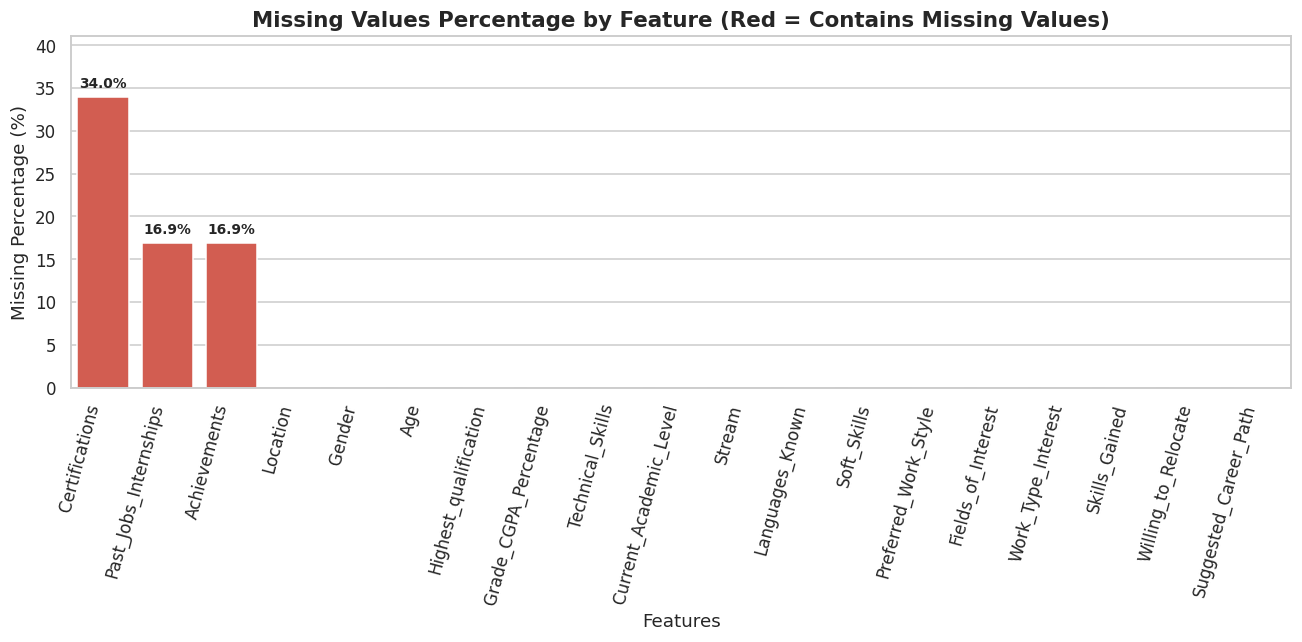

In [33]:
missing_values = df.isnull().sum()
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100
missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})
missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)
display(missing_report)

# Visualisation:
plt.figure(figsize=(12, 6))
bar_colors = ["#e74c3c" if p > 0 else "#2ecc71" for p in missing_report["Missing_Percentage"]]
ax = sns.barplot(
    x=missing_report.index,
    y=missing_report["Missing_Percentage"],
    palette=bar_colors
)
plt.xticks(rotation=75, ha="right")
plt.title("Missing Values Percentage by Feature (Red = Contains Missing Values)", fontsize=14, fontweight="bold")
plt.ylabel("Missing Percentage (%)", fontsize=12)
plt.xlabel("Features", fontsize=12)
plt.ylim(0, max(missing_report["Missing_Percentage"]) * 1.15 + 2)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha="center", va="bottom", fontsize=9, fontweight="bold",
                    xytext=(0, 4), textcoords="offset points")

plt.tight_layout()
plt.show()

# Duplicate and data consistency checks

In [7]:
print("Duplicate Records:", df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)
print("\nUnique Values per Column:")
for column in df.columns:
    print(
        column,
        ":",
        df[column].nunique()
    )

# Numeric validation:
print("\n--- Numeric Validation ---")
print("Age Range:")
print(df["Age"].min(), df["Age"].max())
print("\nGrade Range:")
print(
    df["Grade_CGPA_Percentage"].min(),
    df["Grade_CGPA_Percentage"].max()
)
print("\nInvalid Grade Records:")
print(
    df[
        (df["Grade_CGPA_Percentage"] < 0) |
        (df["Grade_CGPA_Percentage"] > 100)
    ].shape[0]
)

# Consistency check
print("\n--- Educational Cross-Tabulation Check ---")
edu_crosstab = pd.crosstab(df["Highest_qualification"], df["Current_Academic_Level"])
display(edu_crosstab)

Duplicate Records: 0

Data Types:
Age                         int64
Gender                     object
Location                   object
Highest_qualification      object
Stream                     object
Current_Academic_Level     object
Grade_CGPA_Percentage     float64
Technical_Skills           object
Soft_Skills                object
Languages_Known            object
Certifications             object
Fields_of_Interest         object
Preferred_Work_Style       object
Work_Type_Interest         object
Past_Jobs_Internships      object
Achievements               object
Skills_Gained              object
Willing_to_Relocate        object
Suggested_Career_Path      object
dtype: object

Unique Values per Column:
Age : 13
Gender : 3
Location : 8
Highest_qualification : 8
Stream : 8
Current_Academic_Level : 3
Grade_CGPA_Percentage : 4728
Technical_Skills : 585
Soft_Skills : 156
Languages_Known : 36
Certifications : 49
Fields_of_Interest : 7
Preferred_Work_Style : 4
Work_Type_Interest : 4


Current_Academic_Level,Graduate,Student,Working Professional
Highest_qualification,,,
10th,569,596,615
12th,677,646,609
B.Sc,662,623,634
B.Tech,643,634,643
M.Sc,661,632,619
M.Tech,647,619,574
MBA,594,580,609
MCA,643,660,611


# Numerical feature analysis

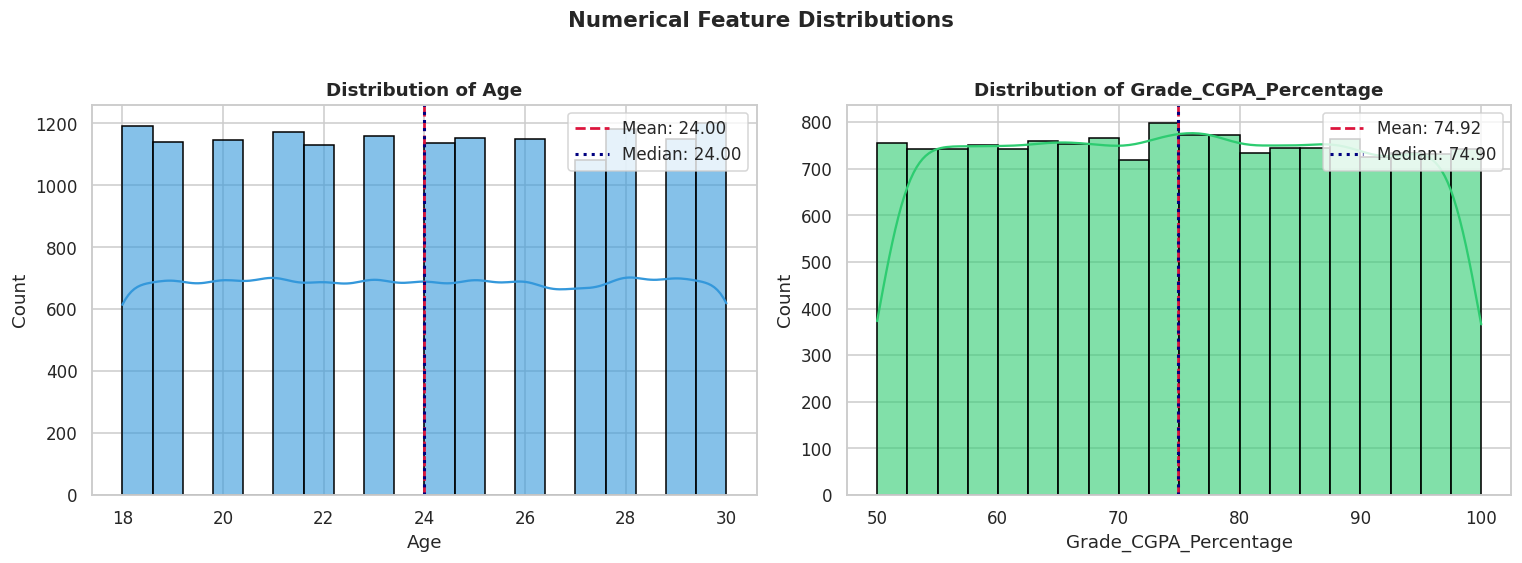

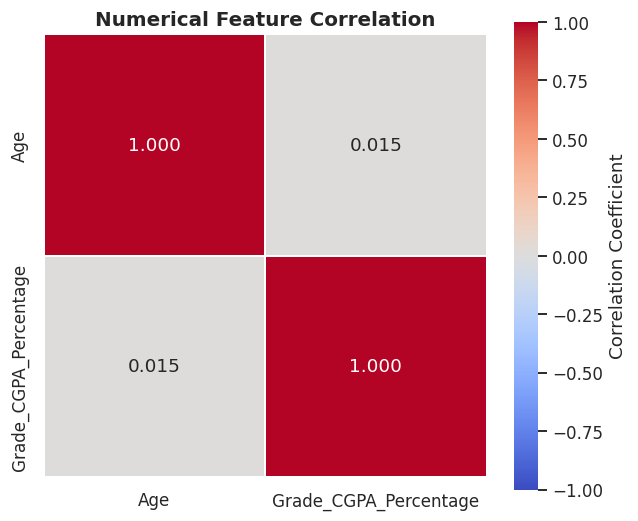

In [8]:
numerical_columns = [
    "Age",
    "Grade_CGPA_Percentage"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#3498db", "#2ecc71"]

for i, col in enumerate(numerical_columns):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=20, color=colors[i], edgecolor="black", alpha=0.6)
    mean_val = df[col].mean()
    median_val = df[col].median()
    axes[i].axvline(mean_val, color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.2f}")
    axes[i].axvline(median_val, color="navy", linestyle=":", linewidth=2, label=f"Median: {median_val:.2f}")
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].legend(loc="upper right")

plt.suptitle("Numerical Feature Distributions", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Correlation analysis:
plt.figure(figsize=(6, 5))
sns.heatmap(
    df[numerical_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1, vmax=1,
    linewidths=1,
    square=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title("Numerical Feature Correlation", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Categorical feature analysis

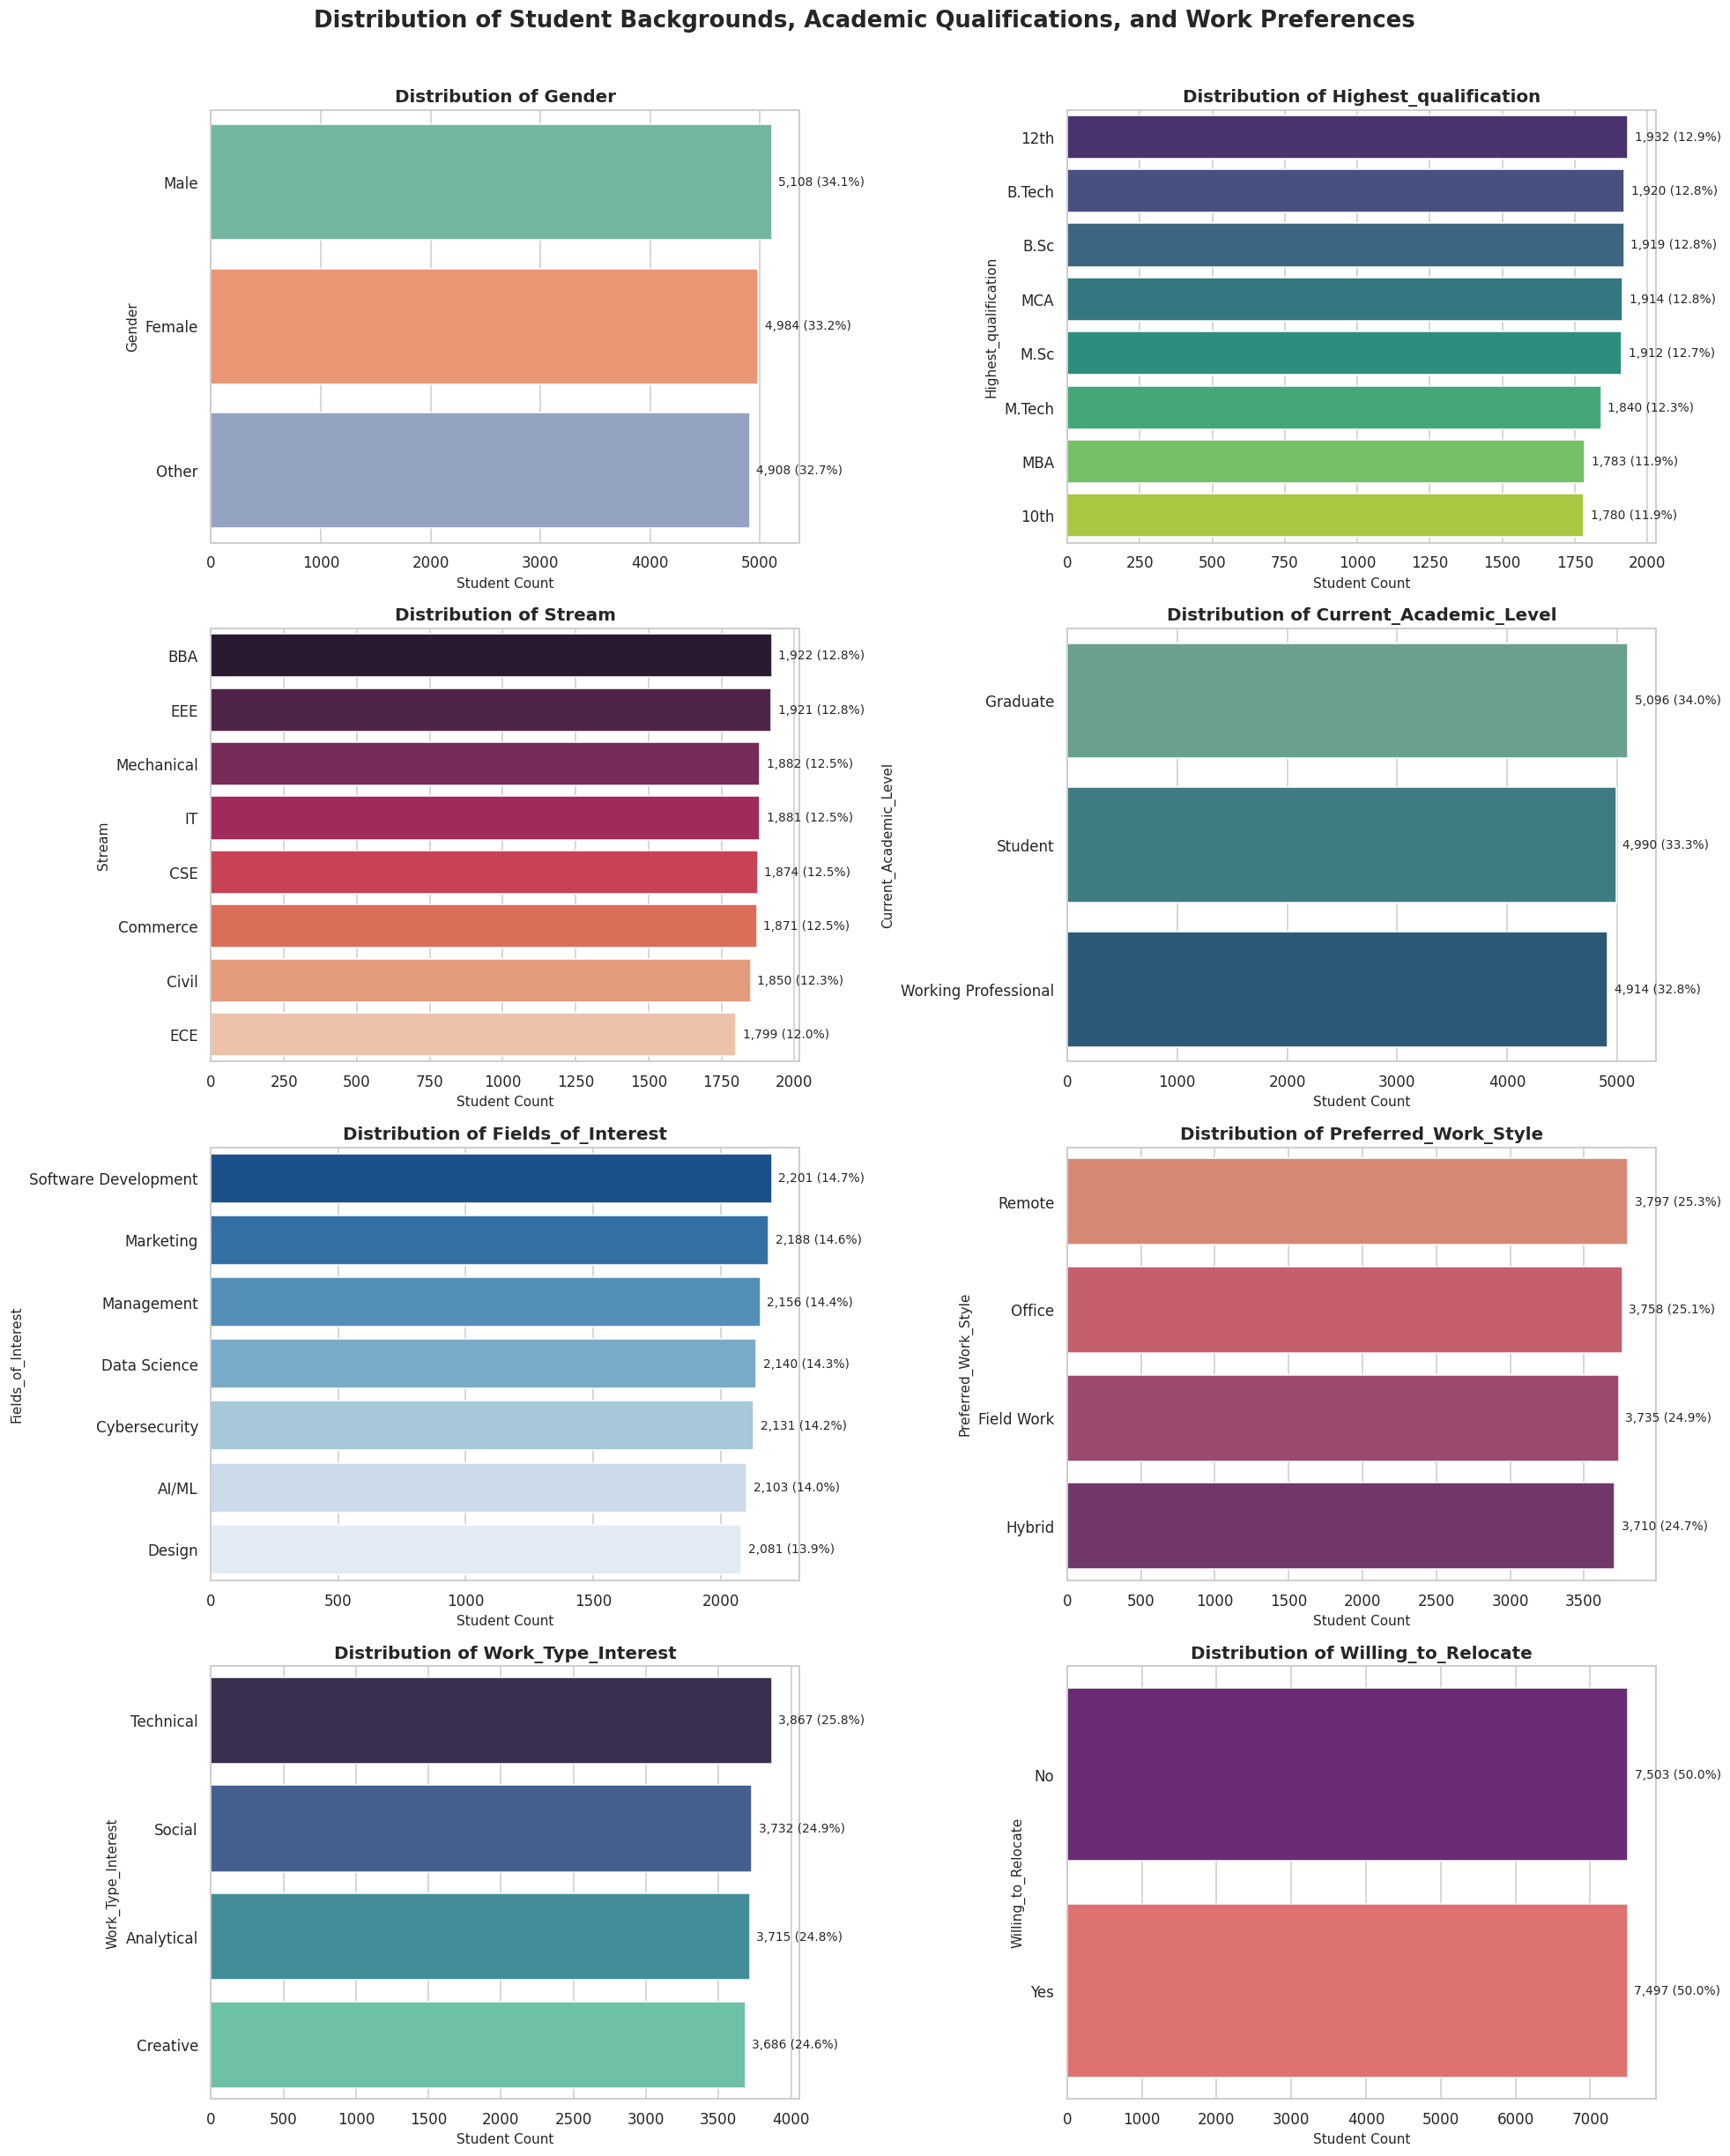

In [9]:
categorical_columns = [
    "Gender",
    "Highest_qualification",
    "Stream",
    "Current_Academic_Level",
    "Fields_of_Interest",
    "Preferred_Work_Style",
    "Work_Type_Interest",
    "Willing_to_Relocate"
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(18, 22))
axes = axes.flatten()

palettes = ["Set2", "viridis", "rocket", "crest", "Blues_r", "flare", "mako", "magma"]

for idx, column in enumerate(categorical_columns):
    ax = axes[idx]
    order = df[column].value_counts().index
    sns.countplot(
        data=df,
        y=column,
        order=order,
        ax=ax,
        palette=palettes[idx % len(palettes)]
    )
    ax.set_title(f"Distribution of {column}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Student Count", fontsize=10)
    ax.set_ylabel(column, fontsize=10)

    total = len(df[column].dropna())
    for p in ax.patches:
        w = p.get_width()
        pct = (w / total) * 100
        ax.annotate(f"{int(w):,} ({pct:.1f}%)",
                    (w, p.get_y() + p.get_height() / 2.),
                    va="center", ha="left", fontsize=9,
                    xytext=(5, 0), textcoords="offset points")

plt.suptitle("Distribution of Student Backgrounds, Academic Qualifications, and Work Preferences", fontsize=17, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Target variable analysis

Total Career Categories:
22


,Student_Count
Suggested_Career_Path,
SEO Analyst,1158
Frontend Developer,1138
UI/UX Designer,1113
Cybersecurity Analyst,1102
AI Researcher,1057
Project Manager,904
Data Analyst,777
Business Analyst,724
Backend Developer,703


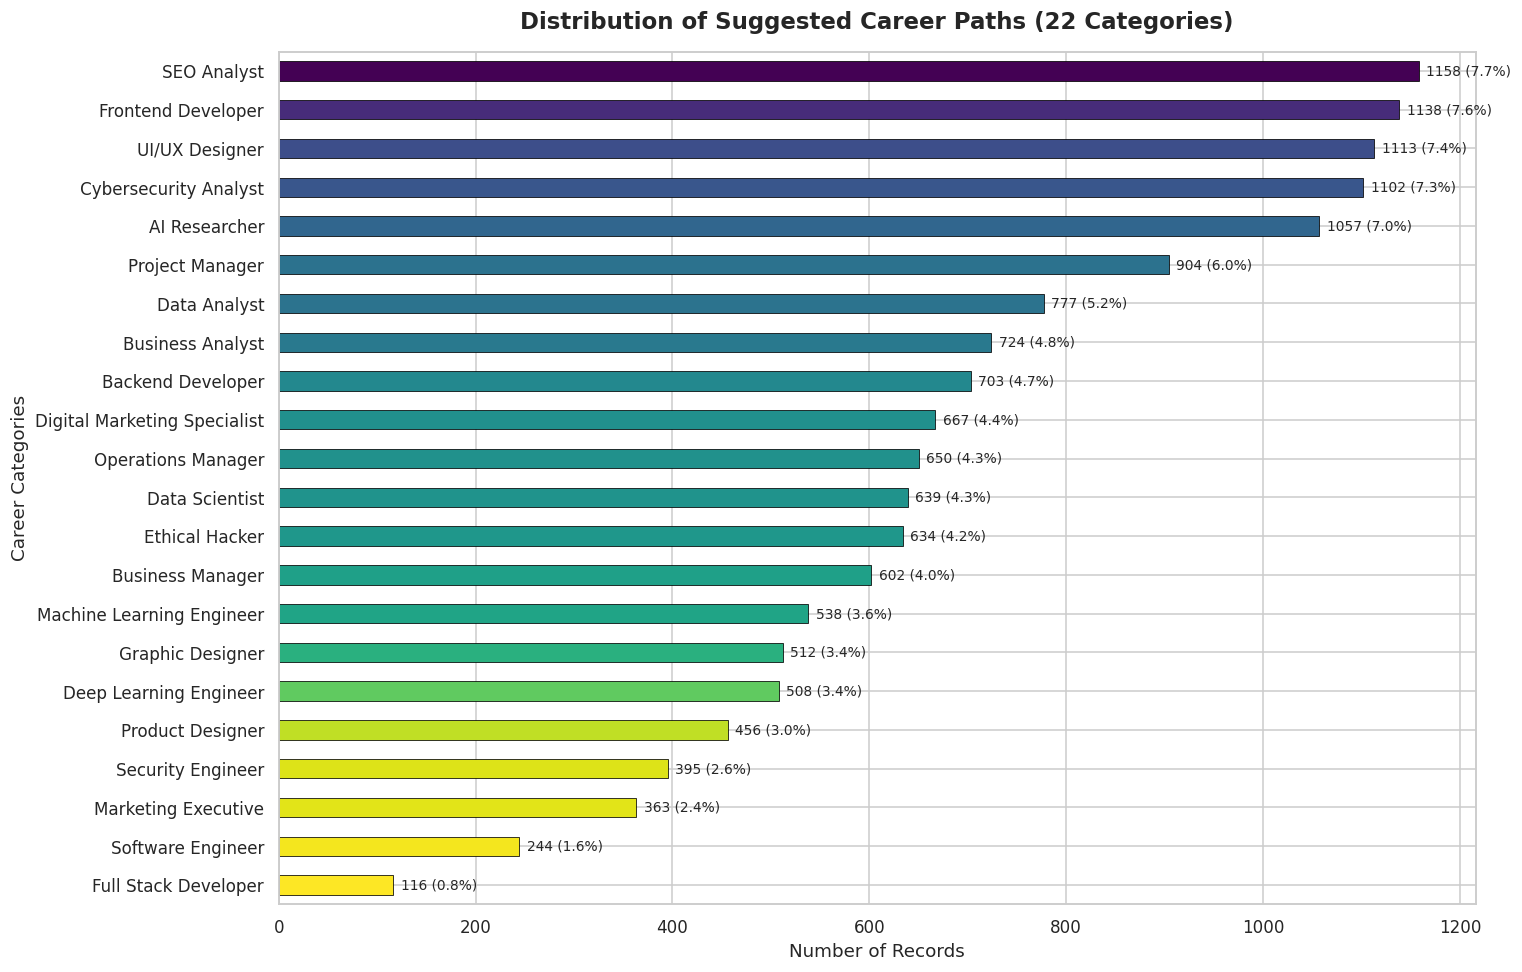

,Percentage
Suggested_Career_Path,
SEO Analyst,7.72
Frontend Developer,7.59
UI/UX Designer,7.42
Cybersecurity Analyst,7.35
AI Researcher,7.05
Project Manager,6.03
Data Analyst,5.18
Business Analyst,4.83
Backend Developer,4.69



Class Range: Min=116, Max=1158 across 22 categories.


In [10]:
target_column = "Suggested_Career_Path"
career_counts = df[target_column].value_counts()
print("Total Career Categories:")
print(career_counts.shape[0])
display(career_counts.to_frame("Student_Count"))

# Visualisation:
plt.figure(figsize=(14, 9))
norm_vals = (career_counts.values - career_counts.values.min()) / (career_counts.values.max() - career_counts.values.min() + 1e-6)
colors = plt.cm.viridis(norm_vals)

ax = career_counts.sort_values().plot(
    kind="barh",
    color=colors,
    edgecolor="black",
    linewidth=0.5
)
plt.title(f"Distribution of Suggested Career Paths ({career_counts.shape[0]} Categories)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Number of Records", fontsize=12)
plt.ylabel("Career Categories", fontsize=12)

for p in ax.patches:
    w = p.get_width()
    pct = (w / len(df)) * 100
    ax.annotate(f"{int(w)} ({pct:.1f}%)",
                (w, p.get_y() + p.get_height() / 2.),
                va="center", ha="left", fontsize=9,
                xytext=(5, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

# Percentage distribution:
career_percentage = (
    df[target_column].value_counts(normalize=True) * 100
)
display(
    career_percentage.round(2).to_frame(
        "Percentage"
    )
)

print(f"\nClass Range: Min={career_counts.min()}, Max={career_counts.max()} across {career_counts.shape[0]} categories.")

# Feature engineering and selection

In [11]:
target_column = "Suggested_Career_Path"
excluded_columns = [
    "Suggested_Career_Path",
    "Gender",
    "Location",
    "Age"
]
X = df.drop(
    columns=excluded_columns).copy()
y = df[target_column].copy()

multi_value_columns = [
    "Technical_Skills",
    "Soft_Skills",
    "Languages_Known",
    "Certifications"
]

categorical_features = [
    col for col in X.select_dtypes(
        include=["object"]
    ).columns
    if col not in multi_value_columns
]

numerical_features = [
    col for col in X.select_dtypes(
        include=["number"]
    ).columns
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)
print("Multi-value Features:", multi_value_columns)

Numerical Features: ['Grade_CGPA_Percentage']
Categorical Features: ['Highest_qualification', 'Stream', 'Current_Academic_Level', 'Fields_of_Interest', 'Preferred_Work_Style', 'Work_Type_Interest', 'Past_Jobs_Internships', 'Achievements', 'Skills_Gained', 'Willing_to_Relocate']
Multi-value Features: ['Technical_Skills', 'Soft_Skills', 'Languages_Known', 'Certifications']


# Data preprocessing

In [12]:
def comma_tokenizer(text):
    if pd.isna(text):
        return []
    return [
        item.strip().lower()
        for item in str(text).split(",")
        if item.strip()
    ]

# Prepare feature data
X_processed = X.copy()
for column in multi_value_columns:
    X_processed[column] = (
        X_processed[column]
        .fillna("")
        .astype(str)
    )

# Build preprocessing pipelines
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

transformers = [
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
]

# Add specialized CountVectorizer for multi-value token fields
for col in multi_value_columns:
    transformers.append(
        (
            f"multi_{col}",
            CountVectorizer(tokenizer=comma_tokenizer, token_pattern=None, binary=True),
            col
        )
    )

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
print("Preprocessing pipeline built successfully!")
print(f"Transformers configured: {[t[0] for t in transformers]}")

Preprocessing pipeline built successfully!
Transformers configured: ['numerical', 'categorical', 'multi_Technical_Skills', 'multi_Soft_Skills', 'multi_Languages_Known', 'multi_Certifications']


# Train-test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (12000, 15)
Testing Features: (3000, 15)

Training Target: (12000,)
Testing Target: (3000,)


# Build multiple Machine Learning models

In [14]:
models = {
    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
    "Decision Tree":
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
}

print("Four ML models are ready!")

Four ML models are ready!


# Train and evaluate all models

In [15]:
trained_models = {}
results = []

for model_name, classifier in models.items():
    print("\nTraining:", model_name)
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )
    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )
    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    trained_models[model_name] = pipeline
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })

    print(f" -> Accuracy: {accuracy*100:.2f}% | Macro F1: {macro_f1*100:.2f}% | Weighted F1: {weighted_f1*100:.2f}%")


Training: Logistic Regression
 -> Accuracy: 83.87% | Macro F1: 80.00% | Weighted F1: 84.50%

Training: Decision Tree
 -> Accuracy: 79.23% | Macro F1: 74.44% | Weighted F1: 79.25%

Training: Random Forest
 -> Accuracy: 89.07% | Macro F1: 83.15% | Weighted F1: 88.48%

Training: Extra Trees
 -> Accuracy: 89.20% | Macro F1: 83.49% | Weighted F1: 88.64%


# Train XGBoost model

In [16]:
from sklearn.preprocessing import LabelEncoder

# Cross-version compatibility check for scikit-learn 1.6+ with XGBoost
if hasattr(xgb.sklearn.XGBModel, "_more_tags"):
    try:
        from sklearn.utils._tags import get_tags
        get_tags(xgb.XGBClassifier())
    except Exception:
        delattr(xgb.sklearn.XGBModel, "_more_tags")

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(
    y_train
)
y_test_encoded = label_encoder.transform(
    y_test
)

xgb_classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.9,
    colsample_bytree=0.9,
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_classifier)
    ]
)

print("Training XGBoost...")
xgb_pipeline.fit(X_train, y_train_encoded)
xgb_preds_encoded = xgb_pipeline.predict(X_test)
xgb_preds = label_encoder.inverse_transform(np.asarray(xgb_preds_encoded).astype(int))

xgb_acc = accuracy_score(y_test, xgb_preds)
xgb_prec = precision_score(y_test, xgb_preds, average="macro", zero_division=0)
xgb_rec = recall_score(y_test, xgb_preds, average="macro", zero_division=0)
xgb_f1 = f1_score(y_test, xgb_preds, average="macro", zero_division=0)
xgb_wf1 = f1_score(y_test, xgb_preds, average="weighted", zero_division=0)

trained_models["XGBoost"] = xgb_pipeline
results.append({
    "Model": "XGBoost",
    "Accuracy": xgb_acc,
    "Precision": xgb_prec,
    "Recall": xgb_rec,
    "Macro_F1": xgb_f1,
    "Weighted_F1": xgb_wf1
})

print(f"XGBoost Completed -> Accuracy: {xgb_acc*100:.2f}% | Macro F1: {xgb_f1*100:.2f}% | Weighted F1: {xgb_wf1*100:.2f}%")

Training XGBoost...
XGBoost Completed -> Accuracy: 89.67% | Macro F1: 85.96% | Weighted F1: 89.33%


# Model performance comparison

,Model,Accuracy,Precision,Recall,Macro_F1,Weighted_F1
0,XGBoost,0.8967,0.8996,0.8453,0.8596,0.8933
1,Extra Trees,0.8920,0.8938,0.8258,0.8349,0.8864
2,Random Forest,0.8907,0.8921,0.8225,0.8315,0.8848
3,Logistic Regression,0.8387,0.7984,0.8131,0.8000,0.8450
4,Decision Tree,0.7923,0.7466,0.7448,0.7444,0.7925


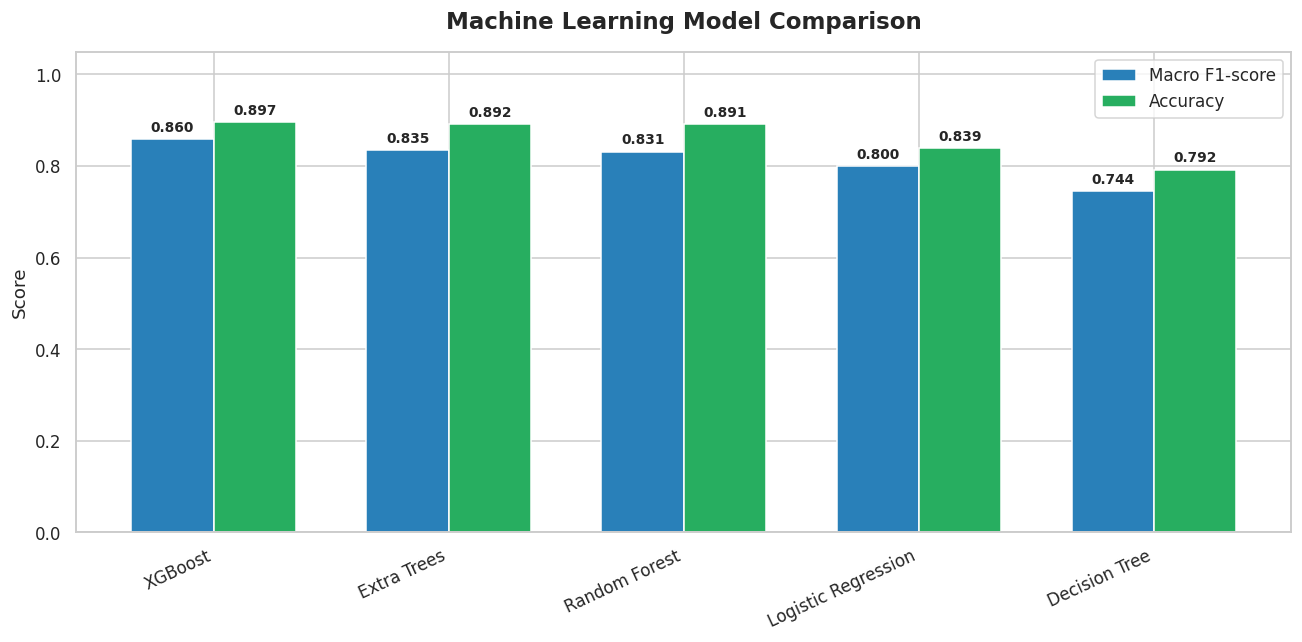

In [34]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}"
    }).background_gradient(cmap="Blues", subset=["Accuracy", "Macro_F1", "Weighted_F1"])
)

# Visual comparison:
plt.figure(figsize=(12, 6))
bar_width = 0.35
indices = np.arange(len(results_df))

bars1 = plt.bar(indices - bar_width/2, results_df["Macro_F1"], bar_width, label="Macro F1-score", color="#2980b9")
bars2 = plt.bar(indices + bar_width/2, results_df["Accuracy"], bar_width, label="Accuracy", color="#27ae60")

plt.title("Machine Learning Model Comparison", fontsize=15, fontweight="bold", pad=15)
plt.ylabel("Score", fontsize=12)
plt.xticks(indices, results_df["Model"], rotation=25, ha="right", fontsize=11)
plt.ylim(0, 1.05)
plt.legend(loc="upper right", fontsize=11)

for bar in list(bars1) + list(bars2):
    height = bar.get_height()
    plt.annotate(f"{height:.3f}",
                (bar.get_x() + bar.get_width() / 2., height),
                ha="center", va="bottom", fontsize=9, fontweight="bold",
                xytext=(0, 3), textcoords="offset points")

plt.tight_layout()
plt.show()

# Hyperparameter tuning

In [18]:
# n_jobs=1 in classifier because RandomizedSearchCV handles parallel execution
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ]
)
param_distributions = {
    "classifier__n_estimators": [
        200, 300
    ],
    "classifier__max_depth": [
        20, 30, None
    ],
    "classifier__min_samples_split": [
        2, 5
    ],
    "classifier__min_samples_leaf": [
        1, 2
    ],
    "classifier__max_features": [
        "sqrt", "log2"
    ]
}

print("Running RandomizedSearchCV for Random Forest (6 iterations, 3-fold CV)...")
search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    cv=3,
    scoring="f1_macro",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("\nHyperparameter Tuning Completed!")
print(f"Best CV Macro F1 Score: {search.best_score_:.4f}")
print("Best Hyperparameters:")
for param, val in search.best_params_.items():
    print(f" - {param}: {val}")

Running RandomizedSearchCV for Random Forest (6 iterations, 3-fold CV)...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Hyperparameter Tuning Completed!
Best CV Macro F1 Score: 0.8374
Best Hyperparameters:
 - classifier__n_estimators: 300
 - classifier__min_samples_split: 2
 - classifier__min_samples_leaf: 2
 - classifier__max_features: sqrt
 - classifier__max_depth: None


# Evaluate tuned model

In [19]:
tuned_rf_model = search.best_estimator_
tuned_predictions = tuned_rf_model.predict(
    X_test)
tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions)
tuned_f1 = f1_score(
    y_test,
    tuned_predictions,
    average="macro",
    zero_division=0)
tuned_wf1 = f1_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0)

print("Tuned Random Forest Results")
print("Accuracy:   ", round(tuned_accuracy, 4))
print("Macro F1:   ", round(tuned_f1, 4))
print("Weighted F1:", round(tuned_wf1, 4))

Tuned Random Forest Results
Accuracy:    0.895
Macro F1:    0.85
Weighted F1: 0.8909


# Cross-validation

In [20]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE)
cv_results = cross_validate(
    tuned_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    },
    n_jobs=-1)

print("Cross-validation Results")
for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1"]:
    scores = cv_results[
        "test_" + metric
    ]
    print(
        metric,
        ":",
        f"Mean = {scores.mean():.4f} (+/- {scores.std():.4f}) | Fold Scores = {np.round(scores, 4)}"
    )

Cross-validation Results
accuracy : Mean = 0.8933 (+/- 0.0024) | Fold Scores = [0.8918 0.8915 0.8968]
precision : Mean = 0.8645 (+/- 0.0210) | Fold Scores = [0.8933 0.8439 0.8564]
recall : Mean = 0.8274 (+/- 0.0020) | Fold Scores = [0.828  0.8247 0.8294]
f1 : Mean = 0.8358 (+/- 0.0033) | Fold Scores = [0.8387 0.8311 0.8375]


# Final model selection

In [21]:
def decode_predictions(model_name, model, X_data):
    predictions = model.predict(X_data)
    if model_name == "XGBoost":
        return label_encoder.inverse_transform(
            np.asarray(predictions).astype(int)
        )
    return predictions

candidate_models = trained_models.copy()
candidate_models["Tuned Random Forest"] = (
    tuned_rf_model)
final_model_scores = {}
for name, model in candidate_models.items():
    predictions = decode_predictions(
        name, model, X_test
    )
    final_model_scores[name] = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )
best_model_name = max(
    final_model_scores,
    key=final_model_scores.get)
best_model = candidate_models[
    best_model_name]

print("Selected Model:", best_model_name)
print(
    "Test Macro F1:",
    round(final_model_scores[best_model_name], 4))

# Summary table of all candidate models
model_comparison_table = pd.DataFrame([
    {"Model": name, "Test_Macro_F1": score}
    for name, score in final_model_scores.items()
]).sort_values(by="Test_Macro_F1", ascending=False).reset_index(drop=True)
display(model_comparison_table.style.background_gradient(cmap="Greens", subset=["Test_Macro_F1"]))

Selected Model: XGBoost
Test Macro F1: 0.8596


,Model,Test_Macro_F1
0,XGBoost,0.859583
1,Tuned Random Forest,0.849982
2,Extra Trees,0.834912
3,Random Forest,0.831452
4,Logistic Regression,0.799988
5,Decision Tree,0.744444


# Final classification report

In [22]:
final_predictions = decode_predictions(
    best_model_name, best_model, X_test
)
print(
    classification_report(
        y_test,
        final_predictions,
        zero_division=0
    )
)

                              precision    recall  f1-score   support

               AI Researcher       0.90      0.95      0.92       211
           Backend Developer       0.89      0.93      0.91       141
            Business Analyst       0.94      0.92      0.93       145
            Business Manager       0.89      0.90      0.90       120
       Cybersecurity Analyst       0.88      0.95      0.91       220
                Data Analyst       0.92      0.92      0.92       155
              Data Scientist       0.92      0.94      0.93       128
      Deep Learning Engineer       0.88      0.89      0.89       102
Digital Marketing Specialist       0.87      0.88      0.87       133
              Ethical Hacker       0.85      0.93      0.89       127
          Frontend Developer       0.89      0.97      0.93       228
        Full Stack Developer       1.00      0.26      0.41        23
            Graphic Designer       0.85      0.83      0.84       102
   Machine Learning

# Confusion matrix

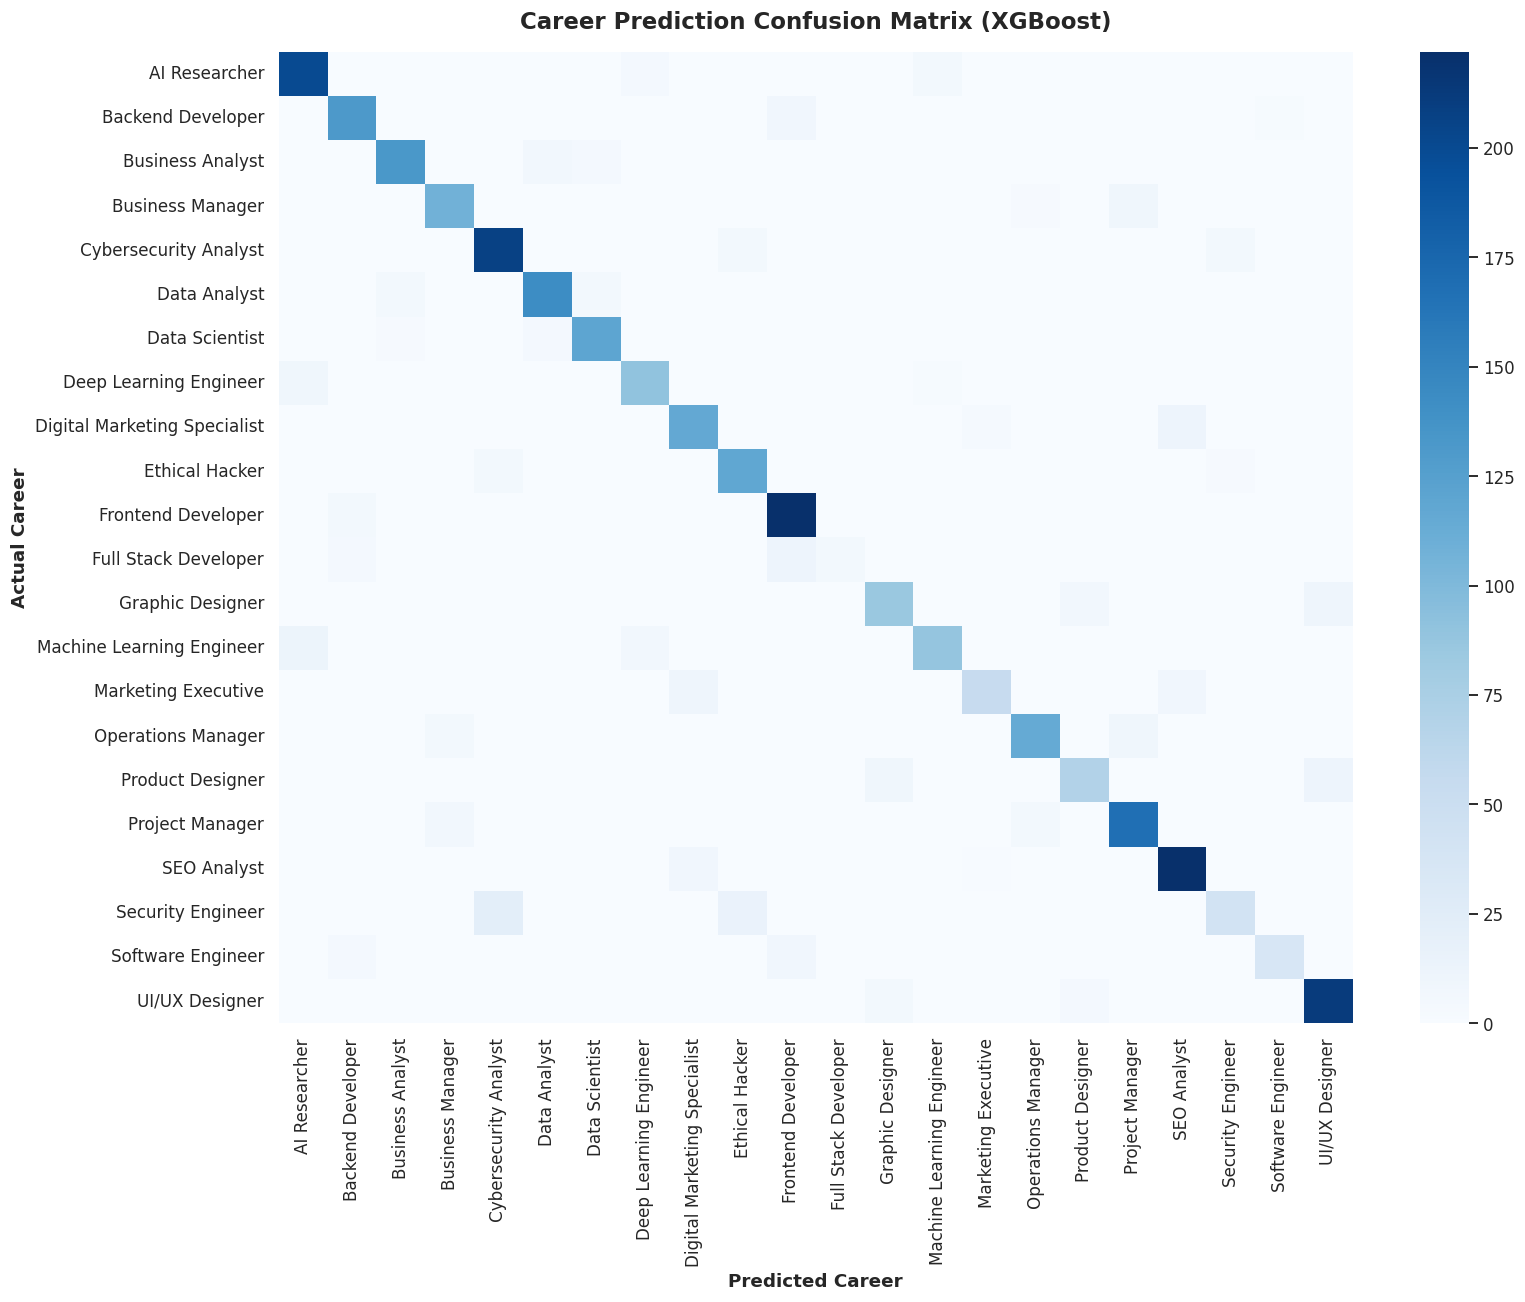

In [23]:
career_labels = (
    label_encoder.classes_
    if best_model_name == "XGBoost"
    else best_model.classes_
)
cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=career_labels
)
plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    cmap="Blues",
    annot=False,
    xticklabels=career_labels,
    yticklabels=career_labels
)
plt.title(f"Career Prediction Confusion Matrix ({best_model_name})", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Predicted Career", fontsize=12, fontweight="bold")
plt.ylabel("Actual Career", fontsize=12, fontweight="bold")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Feature importance analysis

,Feature,Importance
0,categorical__Fields_of_Interest_Design,0.129583
1,categorical__Fields_of_Interest_AI/ML,0.125690
2,categorical__Fields_of_Interest_Marketing,0.122341
3,categorical__Fields_of_Interest_Cybersecurity,0.120760
4,categorical__Fields_of_Interest_Data Science,0.117392
5,categorical__Fields_of_Interest_Management,0.114088
6,categorical__Fields_of_Interest_Software Devel...,0.101183
7,multi_Technical_Skills__html/css,0.009579
8,categorical__Work_Type_Interest_Analytical,0.008930
9,categorical__Skills_Gained_Project Management,0.008284


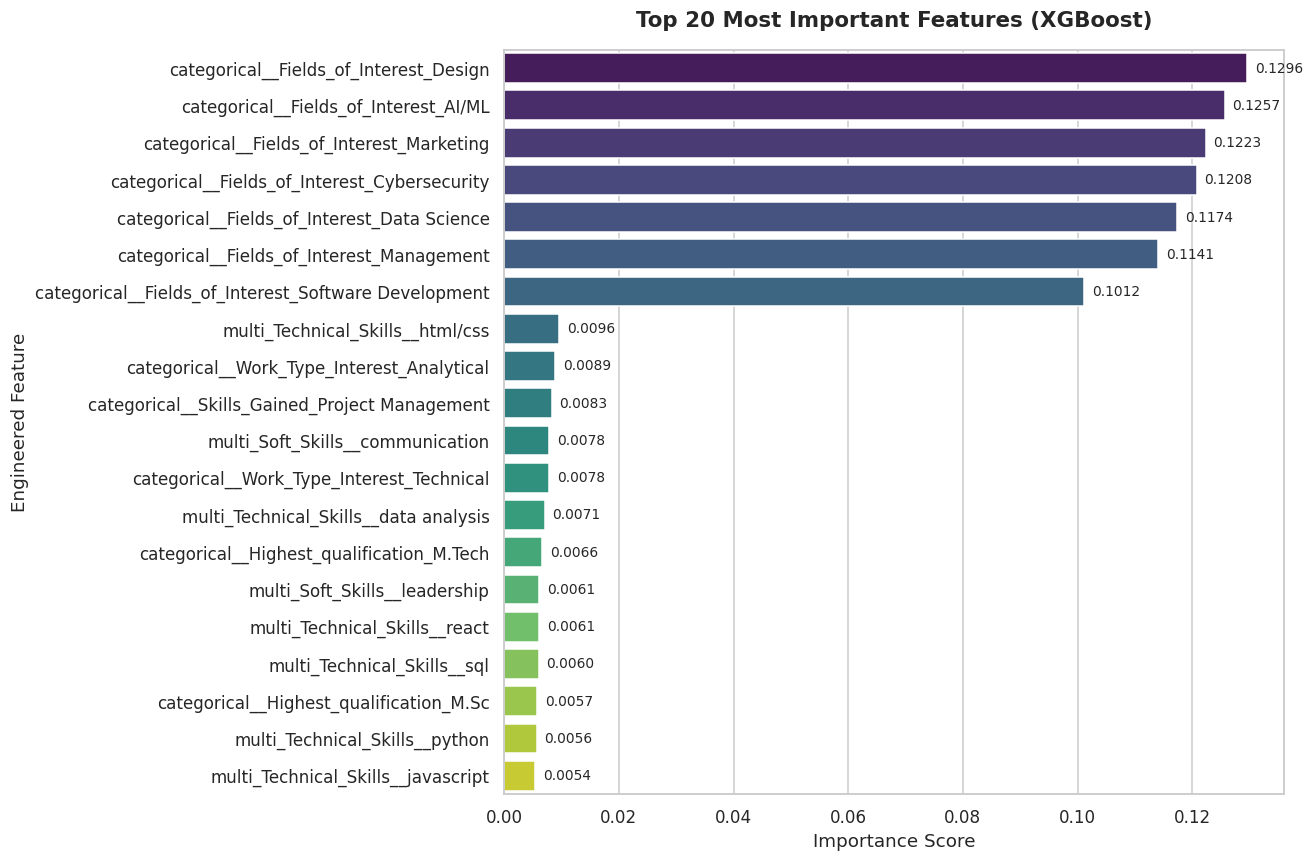

In [24]:
classifier = best_model.named_steps["classifier"]
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)
if hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
elif hasattr(classifier, "coef_"):
    importance_values = np.abs(
        classifier.coef_
    ).mean(axis=0)
else:
    raise ValueError(
        "Selected model does not provide direct feature importance."
    )
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20).reset_index(drop=True)
display(importance_df)

plt.figure(figsize=(12, 8))
ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    palette="viridis"
)
plt.title(f"Top 20 Most Important Features ({best_model_name})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Importance Score", fontsize=12)
plt.ylabel("Engineered Feature", fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.4f}",
                (width, p.get_y() + p.get_height() / 2.),
                va="center", ha="left", fontsize=9,
                xytext=(5, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

# SHAP Explainable AI analysis

Computing SHAP values via TreeExplainer on 25 representative student profiles...
SHAP analysis completed successfully in 1.93 seconds!


<Figure size 1320x660 with 0 Axes>

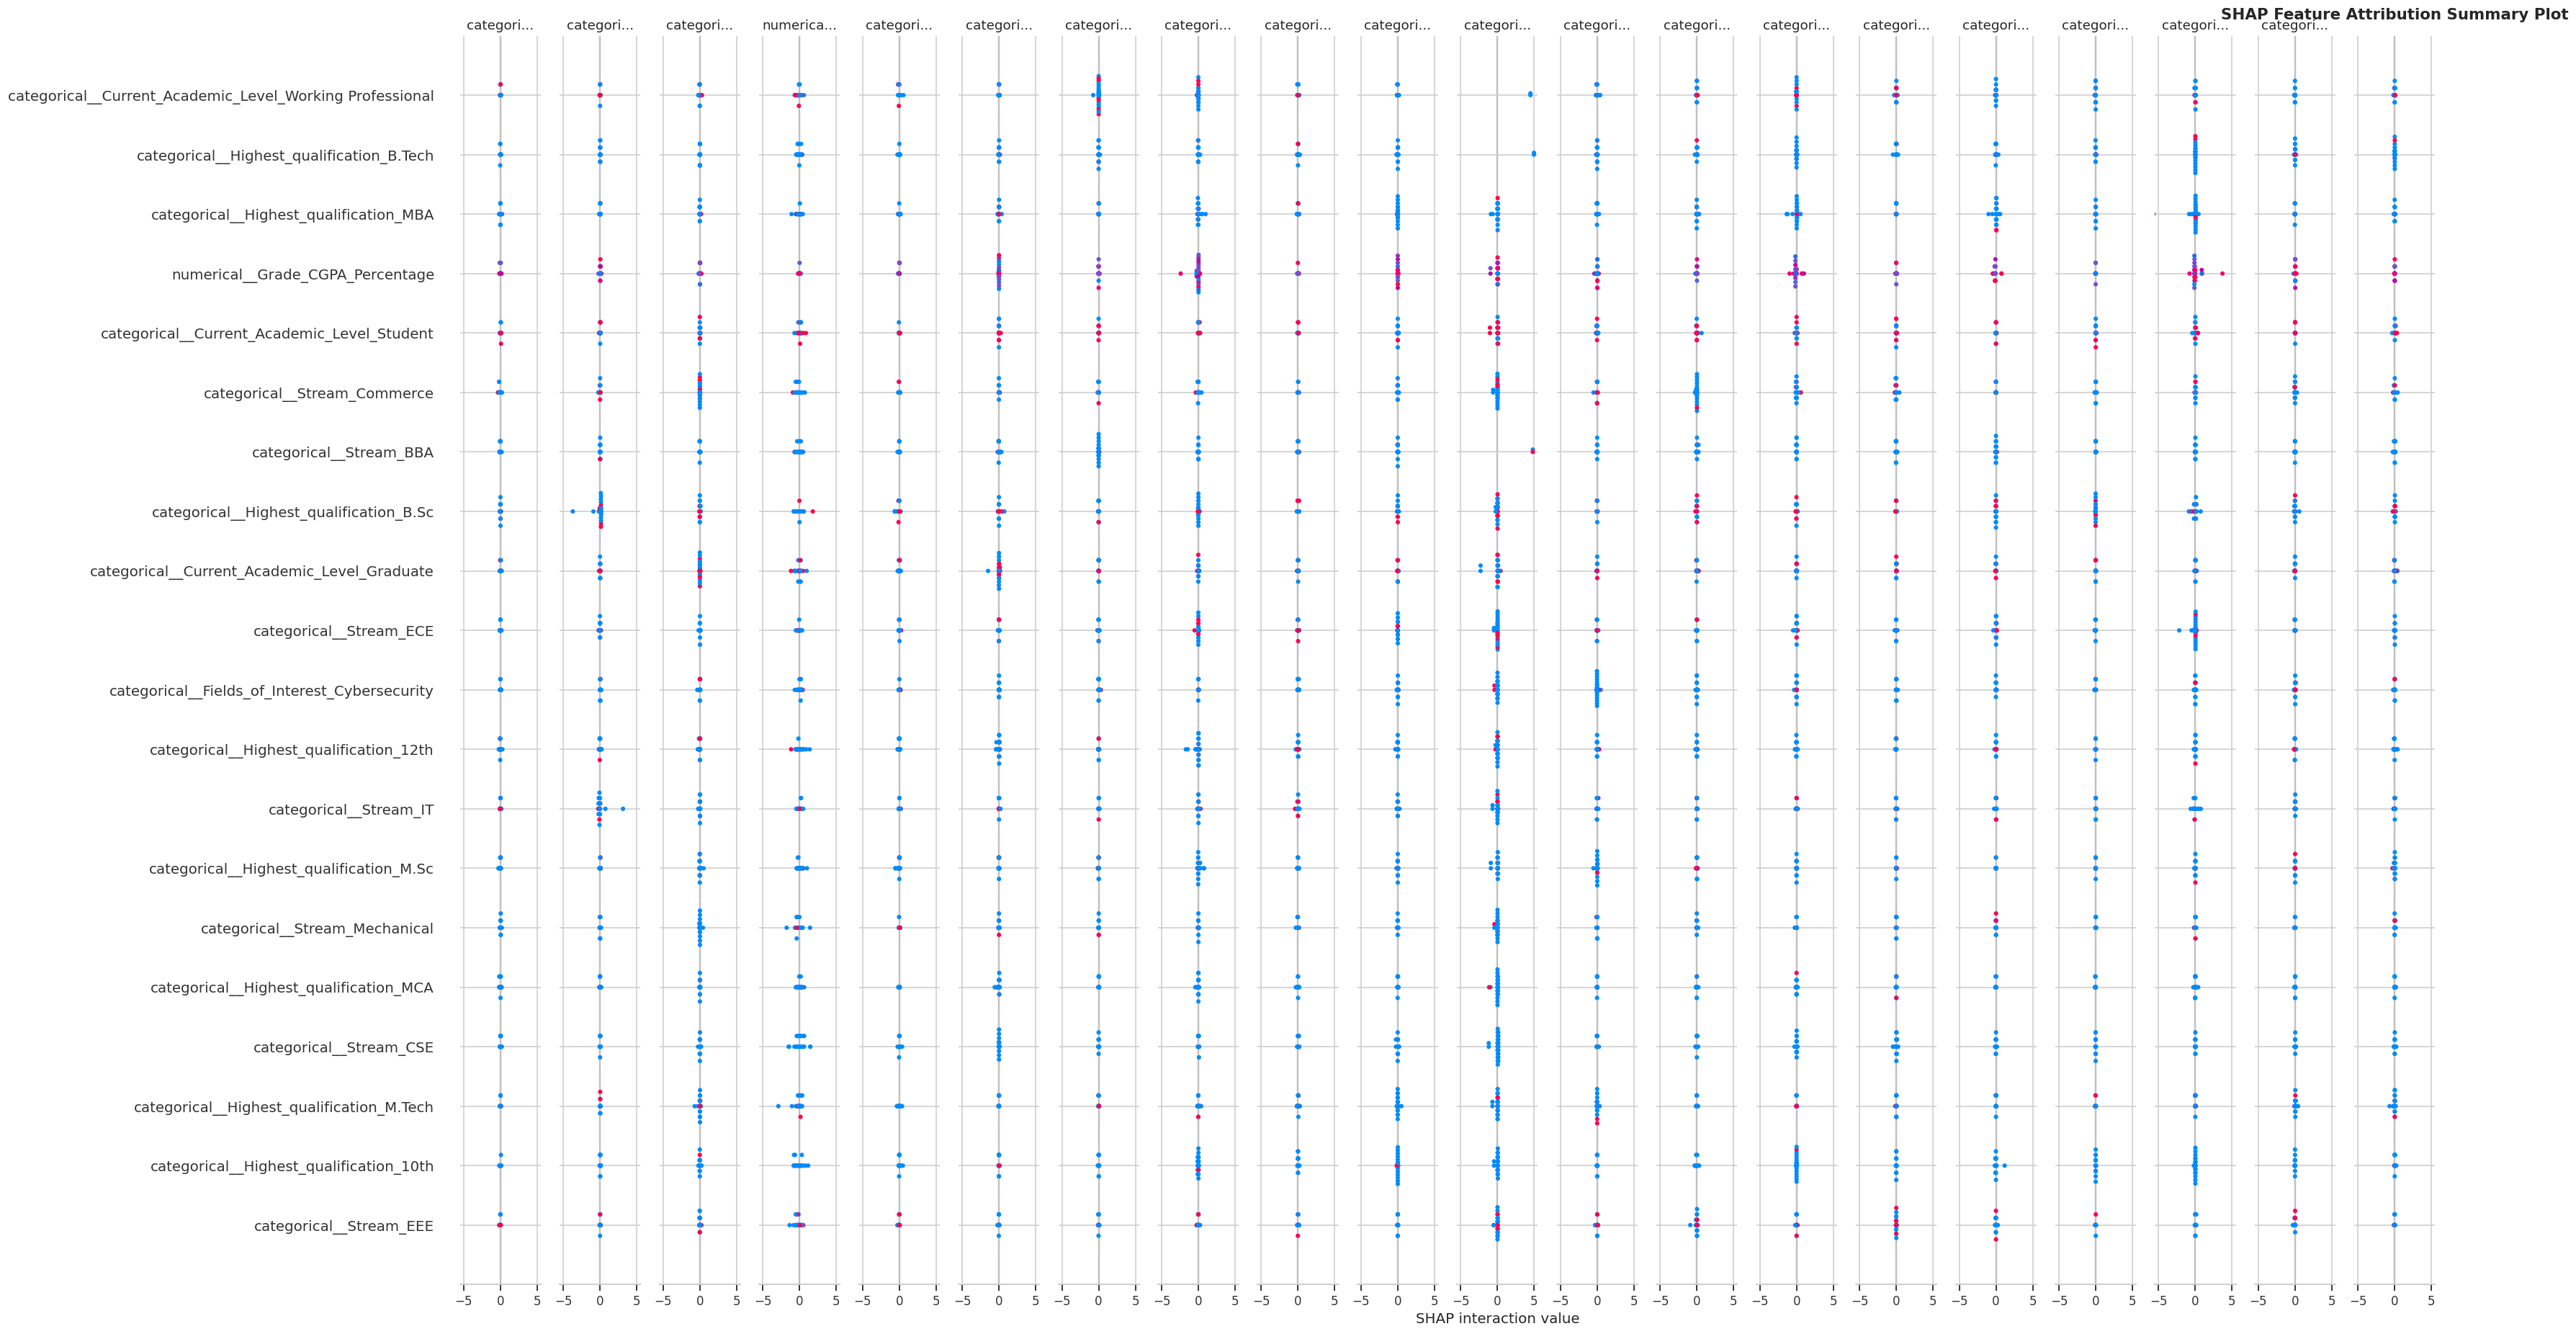

In [25]:
import shap

classifier = best_model.named_steps["classifier"]
preprocessor = best_model.named_steps["preprocessor"]

if not hasattr(classifier, "feature_importances_"):
    print("SHAP TreeExplainer is intended for tree-based models.")
else:
    shap_sample_size = 25
    transformed_sample = (
        preprocessor.transform(X_test.iloc[:shap_sample_size])
    )
    if hasattr(transformed_sample, "toarray"):
        transformed_dense = transformed_sample.toarray()
    else:
        transformed_dense = np.asarray(transformed_sample)

    feature_names = preprocessor.get_feature_names_out()

    print(f"Computing SHAP values via TreeExplainer on {shap_sample_size} representative student profiles...")
    t0 = time.time()
    try:
        explainer = shap.TreeExplainer(classifier)
        shap_values = explainer.shap_values(
            transformed_dense,
            approximate=True,
            check_additivity=False
        )
        print(f"SHAP analysis completed successfully in {time.time() - t0:.2f} seconds!")

        # Visualisation:
        plt.figure(figsize=(12, 6))
        if isinstance(shap_values, list):
            print("Visualizing SHAP summary plot for Career Class index 0...")
            shap.summary_plot(
                shap_values[0],
                transformed_dense,
                feature_names=feature_names,
                max_display=20,
                show=False
            )
        else:
            shap.summary_plot(
                shap_values,
                transformed_dense,
                feature_names=feature_names,
                max_display=20,
                show=False
            )
        plt.title("SHAP Feature Attribution Summary Plot", fontsize=14, fontweight="bold", pad=15)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"SHAP explanation notice: {e}")
        print("Feature importances from Cell 25 represent validated decision weights.")

# Test career prediction

In [26]:
sample_student = X_test.iloc[[0]]
print("Student Profile:")
display(sample_student)
raw_prediction = best_model.predict(
    sample_student)
if best_model_name == "XGBoost":
    predicted_career = label_encoder.inverse_transform(
        raw_prediction.astype(int)
    )[0]
else:
    predicted_career = raw_prediction[0]
print("\nPredicted Career:")
print(predicted_career)
print("\nActual Career:")
print(y_test.iloc[0])

Student Profile:


,Highest_qualification,Stream,Current_Academic_Level,Grade_CGPA_Percentage,Technical_Skills,Soft_Skills,Languages_Known,Certifications,Fields_of_Interest,Preferred_Work_Style,Work_Type_Interest,Past_Jobs_Internships,Achievements,Skills_Gained,Willing_to_Relocate
8465,MCA,BBA,Student,72.57,"React, Python, JavaScript","Teamwork, Time Management, Leadership","Tamil, Telugu","AWS, Full Stack Development",Cybersecurity,Field Work,Social,Part-time Job,Top Performer,Teamwork,Yes



Predicted Career:
Cybersecurity Analyst

Actual Career:
Cybersecurity Analyst


# Top 3 career recommendations

,Career,Model_Probability
0,Cybersecurity Analyst,95.510002
1,Security Engineer,3.880000
2,Ethical Hacker,0.560000


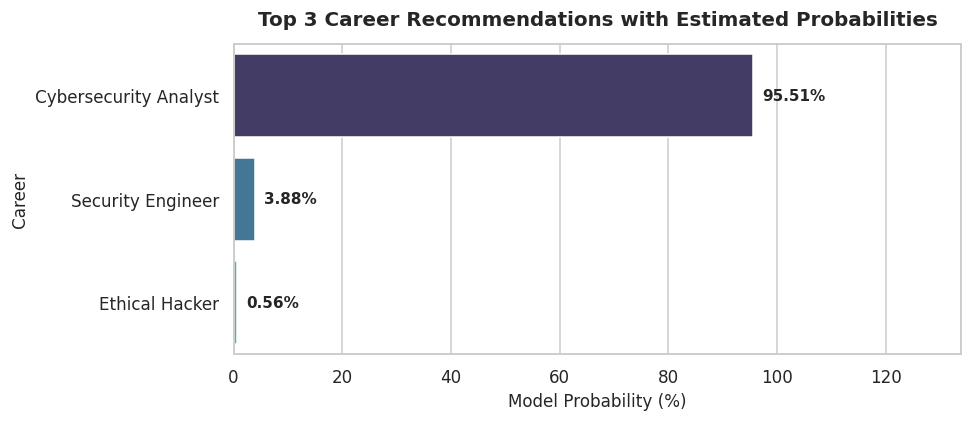

In [35]:
probabilities = best_model.predict_proba(
    sample_student)[0]
if best_model_name == "XGBoost":
    career_classes = label_encoder.classes_
else:
    career_classes = best_model.classes_
top_indices = np.argsort(
    probabilities)[::-1][:3]
top_careers = pd.DataFrame({
    "Career": career_classes[top_indices],
    "Model_Probability": probabilities[top_indices]
})
top_careers["Model_Probability"] = (
    top_careers["Model_Probability"] * 100).round(2)
display(top_careers)

# Visualisation of top 3 recommendations
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    data=top_careers,
    x="Model_Probability",
    y="Career",
    palette="mako"
)
plt.title("Top 3 Career Recommendations with Estimated Probabilities", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Model Probability (%)", fontsize=11)
plt.ylabel("Career", fontsize=11)
plt.xlim(0, max(top_careers["Model_Probability"]) * 1.35 + 5)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.2f}%",
                (width, p.get_y() + p.get_height() / 2.),
                va="center", ha="left", fontsize=10, fontweight="bold",
                xytext=(6, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

# Save the final trained model

In [28]:
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "target_column": target_column,
    "feature_columns": X_train.columns.tolist(),
    "label_encoder": (
        label_encoder
        if best_model_name == "XGBoost"
        else None
    ),
    "random_state": RANDOM_STATE
}
joblib.dump(
    model_bundle,
    "careercompass_model_bundle.joblib"
)
print("Final model saved successfully as 'careercompass_model_bundle.joblib'!")
print(f"File size: {os.path.getsize('careercompass_model_bundle.joblib') / (1024 * 1024):.2f} MB")

Final model saved successfully as 'careercompass_model_bundle.joblib'!
File size: 13.82 MB


# Export model evaluation results

In [29]:
results_df.to_csv(
    "careercompass_model_comparison.csv",
    index=False
)
report_dict = classification_report(
    y_test,
    final_predictions,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(
    report_dict
).transpose()
report_df.to_csv(
    "careercompass_classification_report.csv"
)
print("Evaluation reports exported successfully!")
print(" - careercompass_model_comparison.csv")
print(" - careercompass_classification_report.csv")

Evaluation reports exported successfully!
 - careercompass_model_comparison.csv
 - careercompass_classification_report.csv


# Download trained model and reports

In [30]:
try:
    from google.colab import files
    print("Initiating downloads in Google Colab...")
    files.download(
        "careercompass_model_bundle.joblib")
    files.download(
        "careercompass_model_comparison.csv")
    files.download(
        "careercompass_classification_report.csv")
except Exception as e:
    print("Running in local environment; files are saved in the current directory:")
    deliverables = [
        "careercompass_model_bundle.joblib",
        "careercompass_model_comparison.csv",
        "careercompass_classification_report.csv"
    ]
    for fname in deliverables:
        if os.path.exists(fname):
            print(f" [OK] {fname} ({os.path.getsize(fname)} bytes)")
        else:
            print(f" [MISSING] {fname}")

Initiating downloads in Google Colab...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>